In [21]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))

from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.runnables.config import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore
from pydantic import BaseModel, Field, ValidationError

from utils.models import ModelName, Models, Trace


In [2]:
models = Models()
model_name = ModelName.NEMOTRON_3_5_SUPER_VL_120b_a12b.value
llm = models.create_nvidia_model(model_name=model_name)
in_memory_store = InMemoryStore()

Creating model nvidia/nemotron-3.5-super-vl-120b-a12b


In [3]:
class UserProfile(BaseModel):
    user_name: str = Field(description="user's name")
    interests: list[str] = Field(description="User's Interests")

In [4]:
structured_llm = llm.with_structured_output(UserProfile)
structured_output = structured_llm.invoke(
    [HumanMessage("Hi,I am Jason and I like hiking and cycling")]
)
structured_output

UserProfile(user_name='Jason', interests=['hiking', 'cycling'])

In [5]:
ASSISTANT_INSTRUCTIONS = """You are a helpful assistant with memory that provides relevant information about this user.
If you have memory,personalize your responses.
Here is the memory:{memory}
"""

MEMORY_WRITE_INSTRUCTIONS = """You are collecting useful information about the user.
current user information:{memory}
Instructions:
1. Review the chat history carefully
2. Collect relevant and useful information about the user:
    - Name,location,occupation,interests,hobbies etc
    - Preferences such as likes and dislikes
    - Past experiences
    - Future gaols and plans 
3. When new information arrives, merge with existing ones
4. When conflicting information arrives, use the latest information and discard the old/existing ones 
5.The memory should in clear bulleted list 
6.All the information, should be facts stated by the user do not bring outside information,interferences,assumptions 
based on the chat history update the user information 
"""

In [10]:
def call_llm(state: MessagesState, config: RunnableConfig, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    namespace = ("memory", user_id)
    key = "user_memory"

    existing_memory = store.get(namespace, key)

    if existing_memory:
        existing_memory_content = existing_memory.value.get("memory")
    else:
        existing_memory_content = "No memory found"

    system_message = ASSISTANT_INSTRUCTIONS.format(memory=existing_memory_content)

    response = llm.invoke([SystemMessage(system_message)] + state["messages"])

    return {"messages": response}


In [12]:
def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    namespace = ("memory", user_id)
    key = "user_memory"

    existing_memory = store.get(namespace, key)
    if existing_memory and existing_memory.value:
        memory_dict = existing_memory.value
        formatted_memory = f"Name: {memory_dict.get('user_name', 'unknown')} \n Interests:{memory_dict.get('interests', [])}"

    else:
        formatted_memory = None

    system_message = MEMORY_WRITE_INSTRUCTIONS.format(memory=formatted_memory)

    response = llm.invoke([SystemMessage(content=system_message)] + state["messages"])

    store.put(namespace, key, {"memory": response})


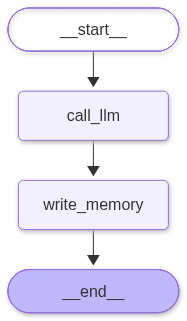

In [13]:
builder = StateGraph(MessagesState)
builder.add_node("call_llm", call_llm)
builder.add_node("write_memory", write_memory)
builder.add_edge(START, "call_llm")
builder.add_edge("call_llm", "write_memory")
builder.add_edge("write_memory", END)
short_term_memory = MemorySaver()
long_term_memory = InMemoryStore()

graph = builder.compile(checkpointer=short_term_memory, store=long_term_memory)

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))


In [14]:
config = {"configurable": {"thread_id": "1", "user_id": "1"}}

# User input
input_messages = [
    HumanMessage(
        content="Hi, my name is Lance and I like to bike around San Francisco and eat at bakeries."
    )
]

# Run the graph
for chunk in graph.stream({"messages": input_messages}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()


================================ Human Message =================================

Hi, my name is Lance and I like to bike around San Francisco and eat at bakeries.
================================== Ai Message ==================================

Hi Lance! Great to meet you. San Francisco is an amazing city for combining bike rides with bakery stops.

Do you have a favorite neighborhood you like to ride through—maybe the Mission, along the Embarcadero, or up toward the Presidio? And have you found a go-to bakery yet, or are you still exploring?


In [ ]:
user_id = "1"
namespace = ("memory", user_id)
existing_memory = long_term_memory.get(namespace, key="user_memory")


'Based on your message, here is the information collected about you:\n\n- Name: Lance\n- Location/activity: Bikes around San Francisco\n- Interests/hobbies: Eating at bakeries, biking'

In [18]:
print(existing_memory.value["memory"].content)

Based on your message, here is the information collected about you:

- Name: Lance
- Location/activity: Bikes around San Francisco
- Interests/hobbies: Eating at bakeries, biking


#### When this fails?
- `with_structured_output` is very useful but what happens when working with a complex schema or a nested schema
- Here is an example

In [34]:
llm_new = models.create_nvidia_model(model_name=ModelName.NEMOTRON_ULTRA_3_550b.value)

Creating model nvidia/nemotron-3-ultra-550b-a55b


In [44]:
class OutputFormat(BaseModel):
    preference: str
    sentence_preference_revealed: str


class TelegramPreferences(BaseModel):
    preferred_encoding: list[OutputFormat] | None
    favorite_telegram_operators: list[OutputFormat] | None
    preferred_telegram_paper: list[OutputFormat] | None


class MorseCode(BaseModel):
    preferred_key_type: list[OutputFormat] | None
    favorite_morse_abbreviations: list[OutputFormat] | None


class Semaphore(BaseModel):
    preferred_flag_color: list[OutputFormat] | None
    semaphore_skill_level: list[OutputFormat] | None


class TrustFallPreferences(BaseModel):
    preferred_fall_height: list[OutputFormat] | None
    trust_level: list[OutputFormat] | None
    preferred_catching_technique: list[OutputFormat] | None


class CommunicationPreferences(BaseModel):
    telegram: TelegramPreferences
    morse_code: MorseCode
    semaphore: Semaphore


class UserPreferences(BaseModel):
    communication_preferences: CommunicationPreferences
    trust_fall_preferences: TrustFallPreferences


class TelegramAndTrustFallPreferences(BaseModel):
    pertinent_user_preferences: UserPreferences


In [45]:
model_with_structure_new = llm_new.with_structured_output(
    TelegramAndTrustFallPreferences
)

In [42]:
# Conversation
conversation = """Operator: How may I assist with your telegram, sir?
Customer: I need to send a message about our trust fall exercise.
Operator: Certainly. Morse code or standard encoding?
Customer: Morse, please. I love using a straight key.
Operator: Excellent. What's your message?
Customer: Tell him I'm ready for a higher fall, and I prefer the diamond formation for catching.
Operator: Done. Shall I use our "Daredevil" paper for this daring message?
Customer: Perfect! Send it by your fastest carrier pigeon.
Operator: It'll be there within the hour, sir."""


In [46]:
try:
    model_with_structure_new.invoke(f"""Extract the preferences from the following conversation:
    <convo>
    {conversation}
    </convo>""")
except ValidationError as e:
    print(e)

#### Trustcall for creating and updating profile schemas

- As we can see, working with schemas can be tricky.
- Complex schemas can be difficult to extract. 
- In addition, updating even simple schemas can pose challenges.
- Consider our above chatbot. 
- We regenerated the profile schema *from scratch* each time we chose to save a new memory.
- This is inefficient, potentially wasting model tokens if the schema contains a lot of information to re-generate each time.
- Worse, we may loose information when regenerating the profile from scratch.
- Addressing these problems is the motivation for [TrustCall](https://github.com/hinthornw/trustcall)!
- This is an open-source library for updating JSON schemas developed by one [Will Fu-Hinthorn](https://github.com/hinthornw) on the LangChain team.
- It's motivated by exactly these challenges while working on memory.
- Let's first show simple usage of extraction with TrustCall on this list of [messages](https://docs.langchain.com/oss/python/langchain/messages).
